
 Processing Profile: GK
 Target Positions: ['GK'] | Target Sides: ['C']


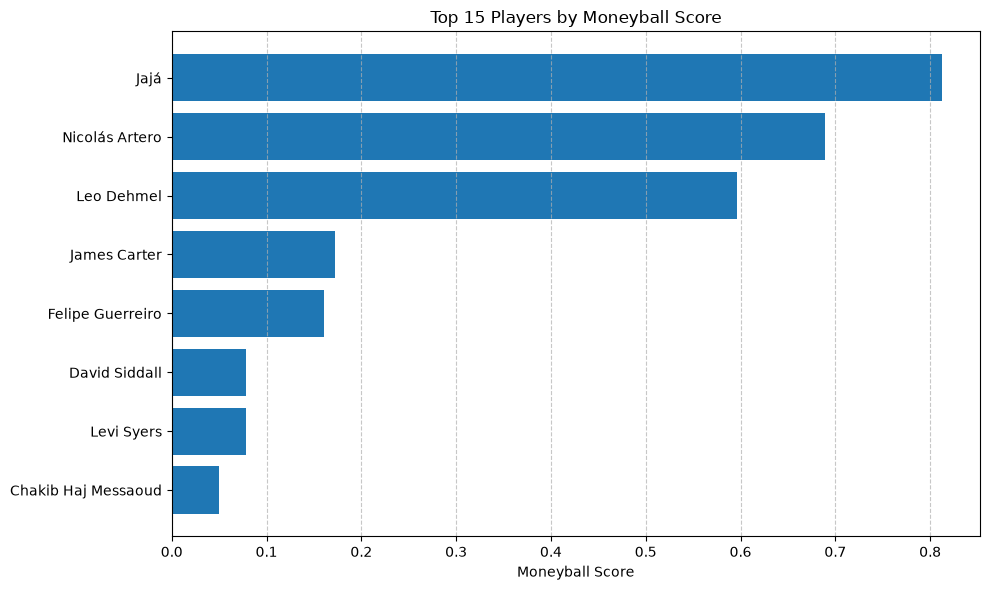

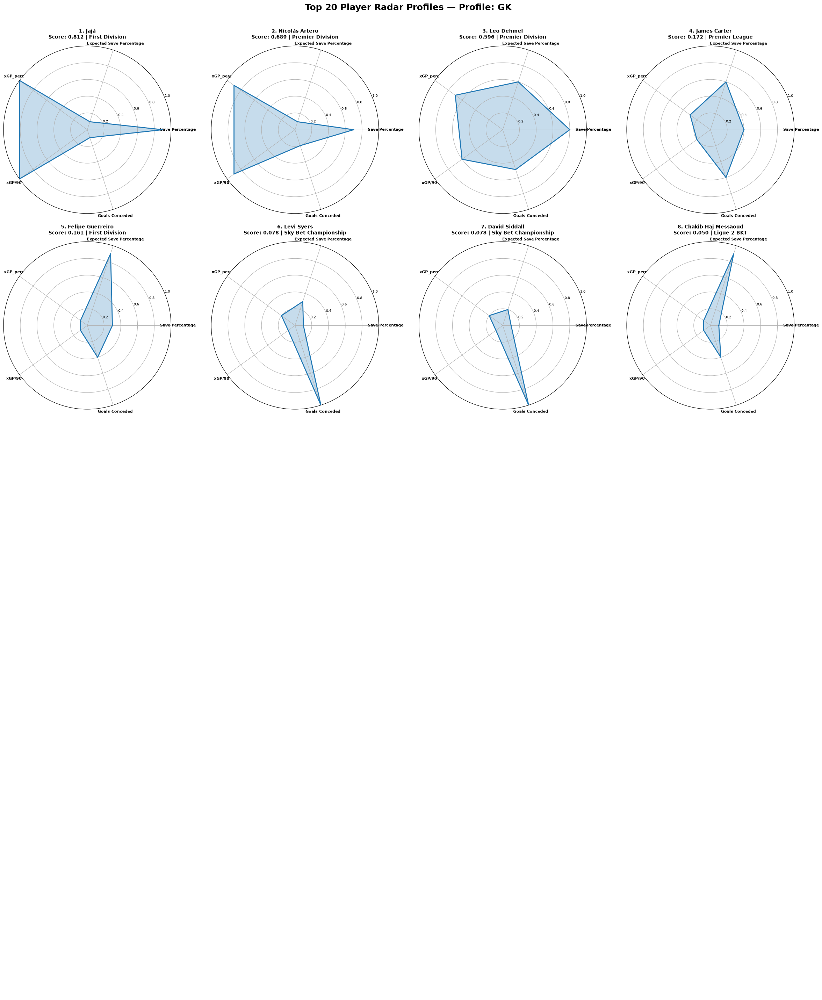

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


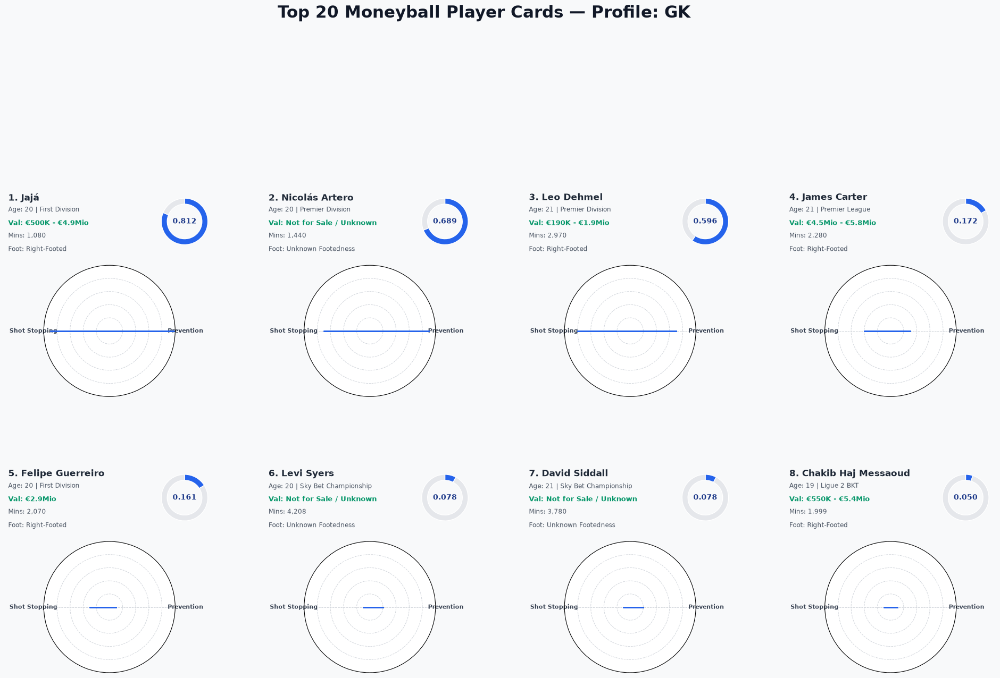

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


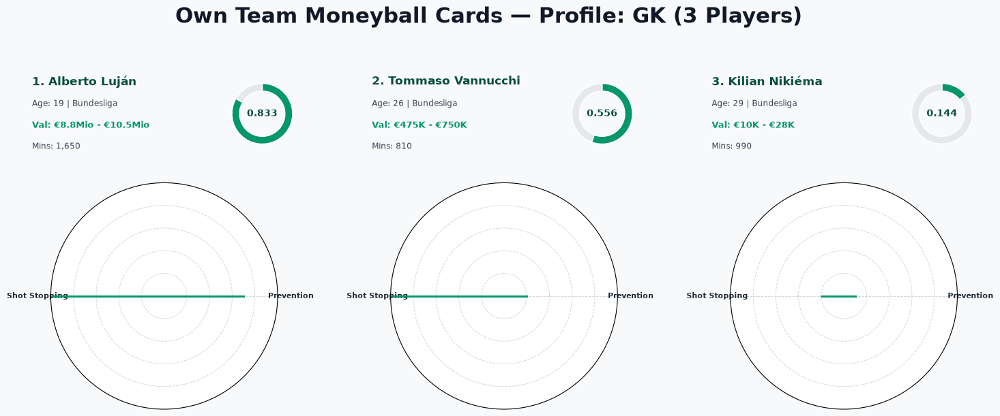

Cards successfully generated and saved to 'own_team_gk_scouting_cards.png'
 Finished generating charts for profile: GK

 Processing Profile: CB_Cover
 Target Positions: ['D'] | Target Sides: ['C']


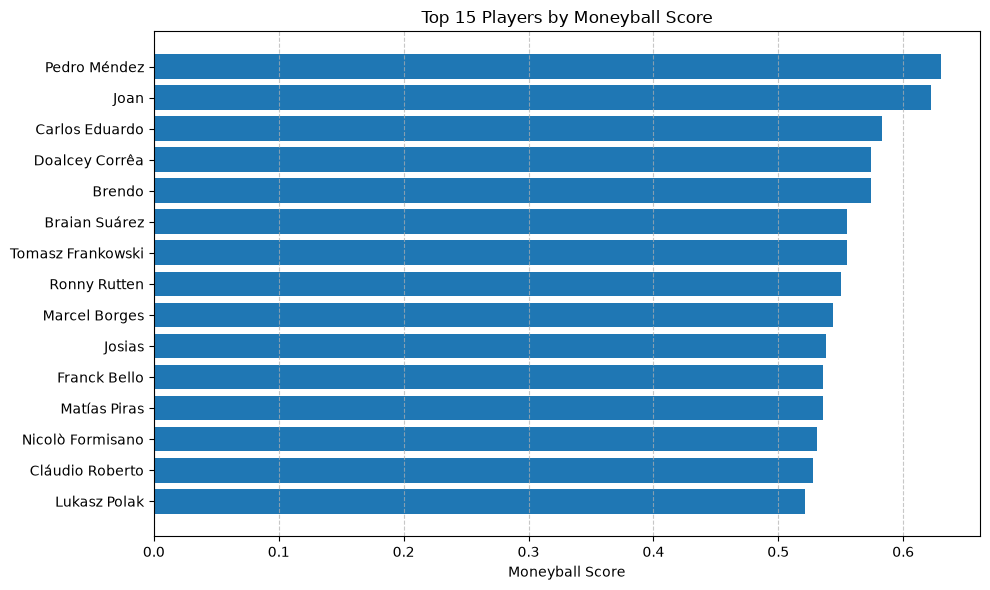

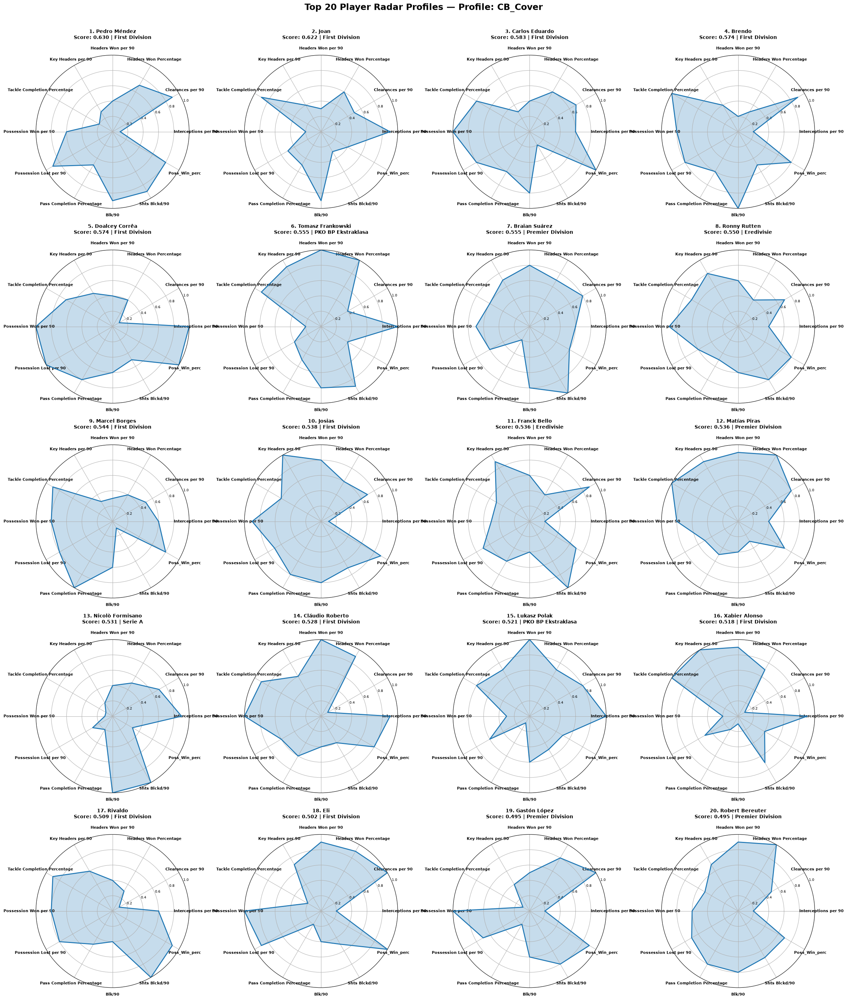

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


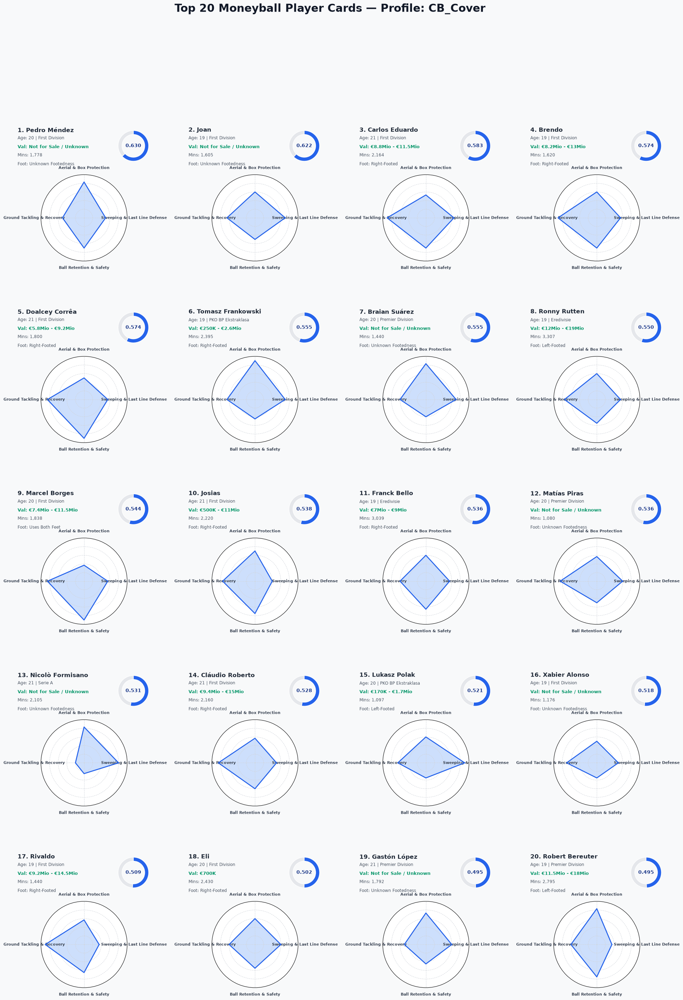

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


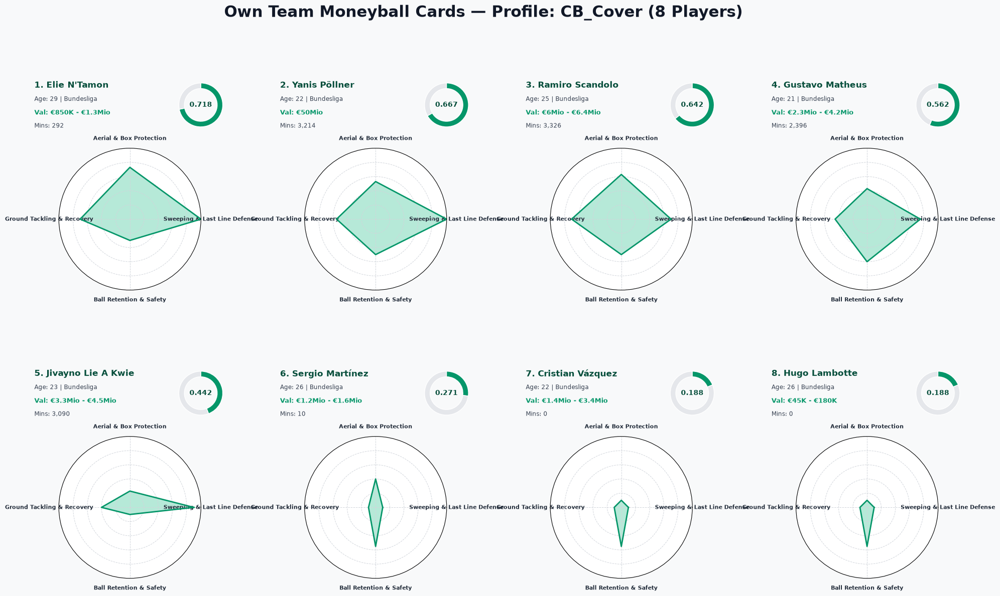

Cards successfully generated and saved to 'own_team_cb_cover_scouting_cards.png'
 Finished generating charts for profile: CB_Cover

 Processing Profile: WCB_Gegenpress
 Target Positions: ['D'] | Target Sides: ['C']


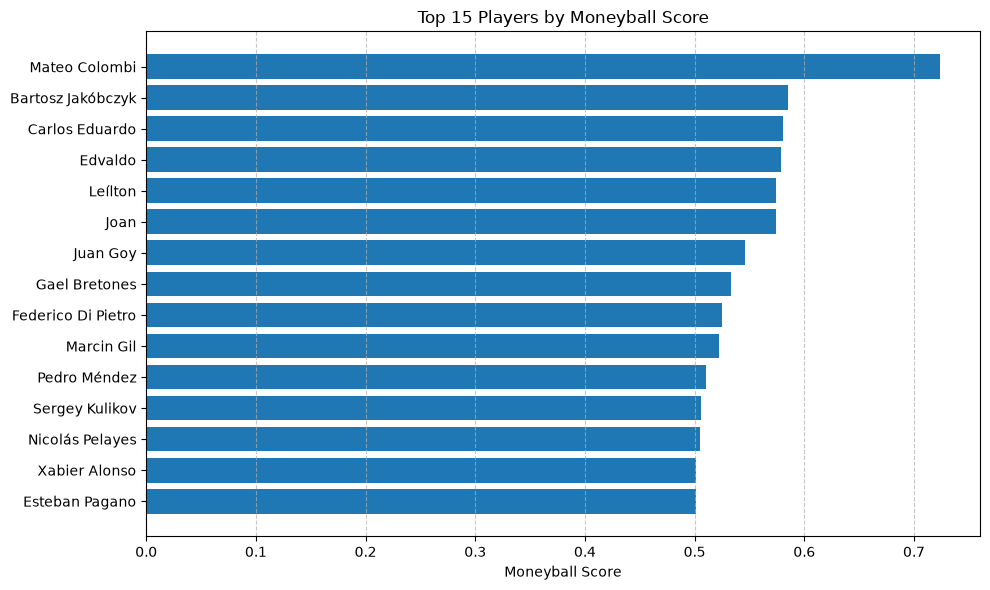

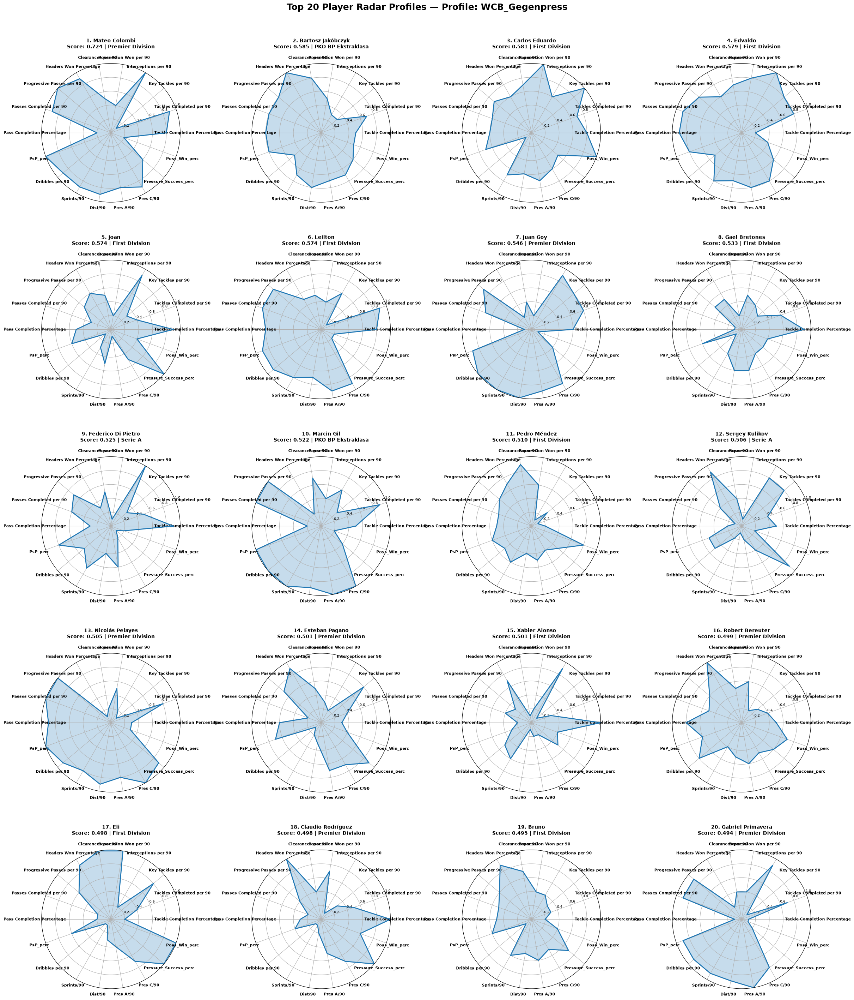

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


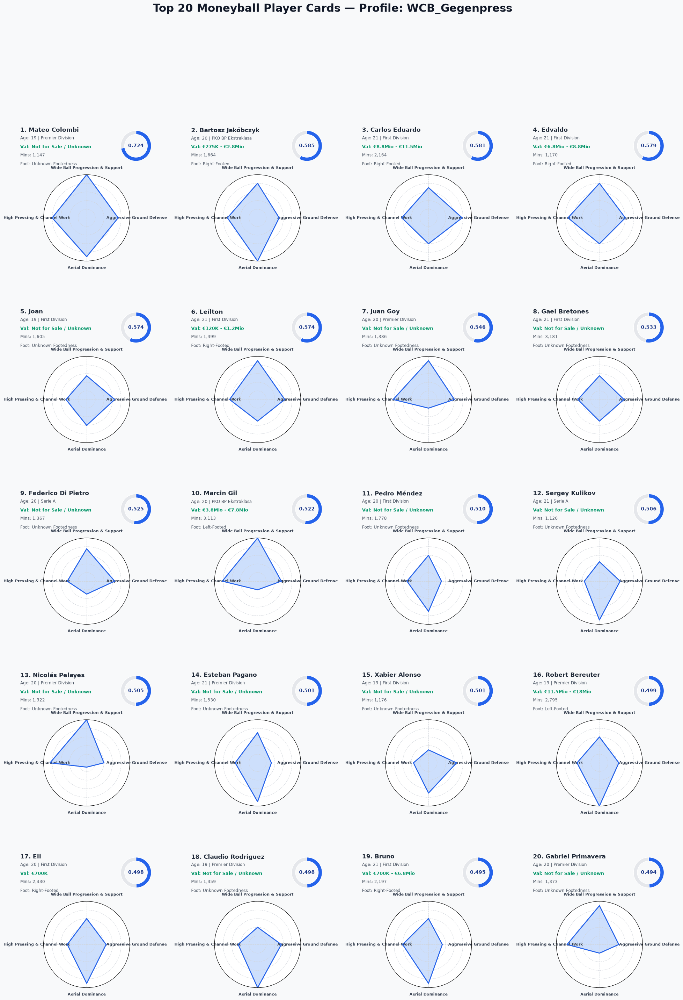

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


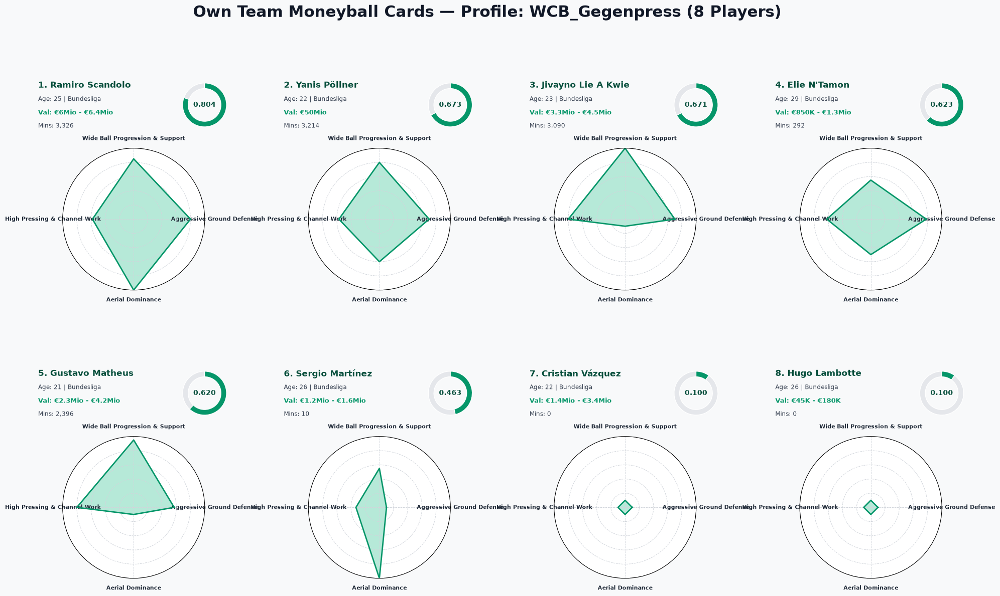

Cards successfully generated and saved to 'own_team_wcb_gegenpress_scouting_cards.png'
 Finished generating charts for profile: WCB_Gegenpress

 Processing Profile: WB_5212
 Target Positions: ['D', 'WB'] | Target Sides: ['R/L']


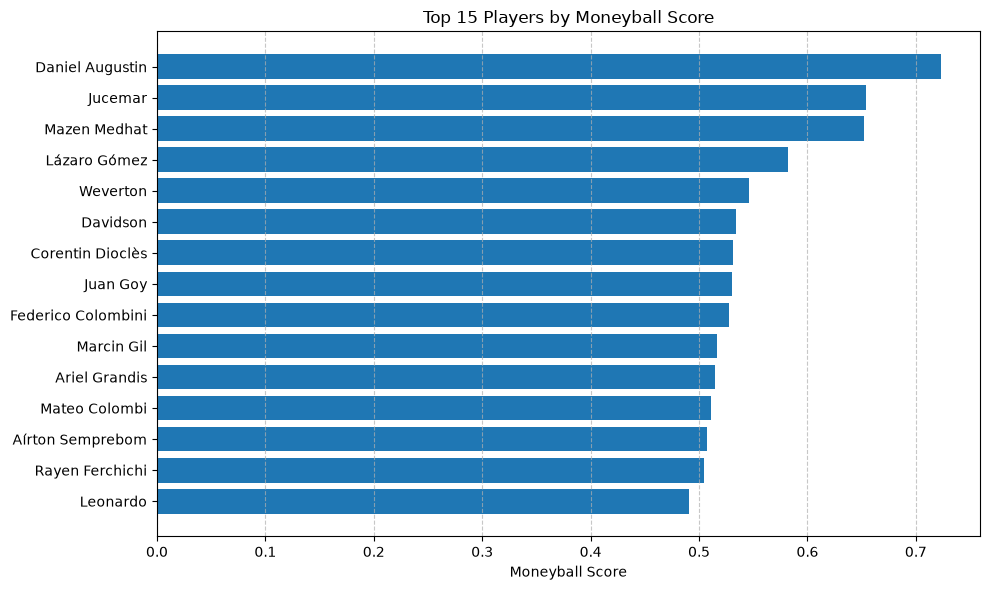

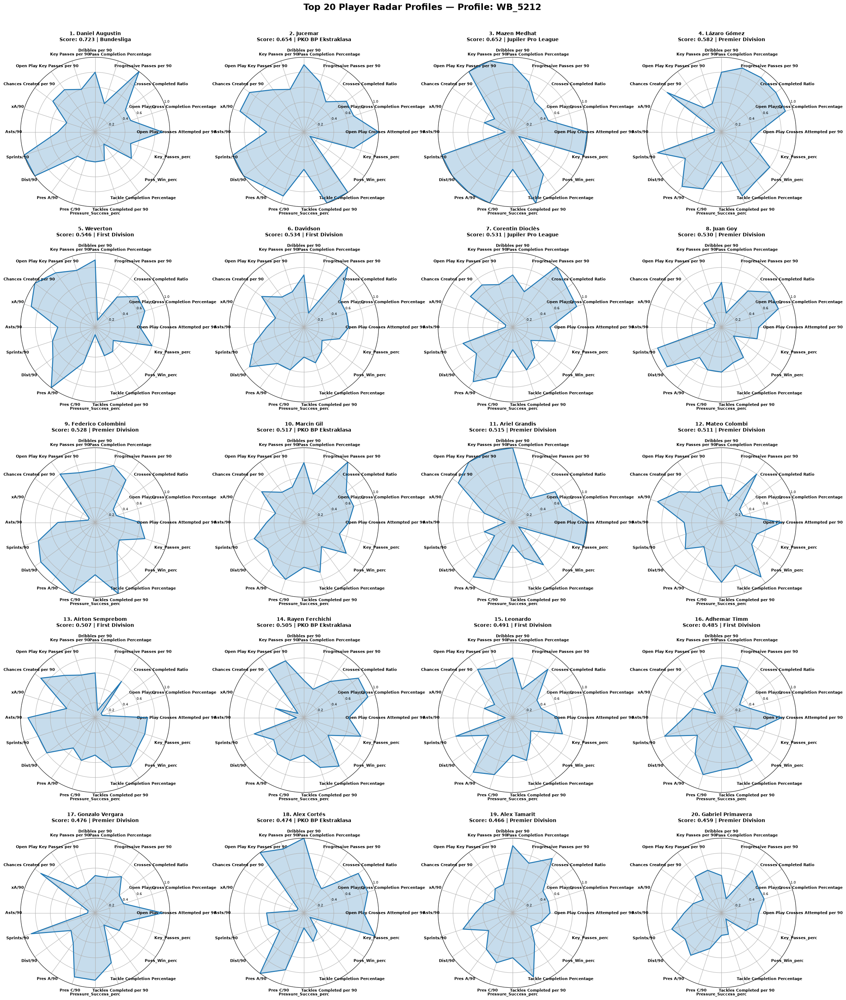

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


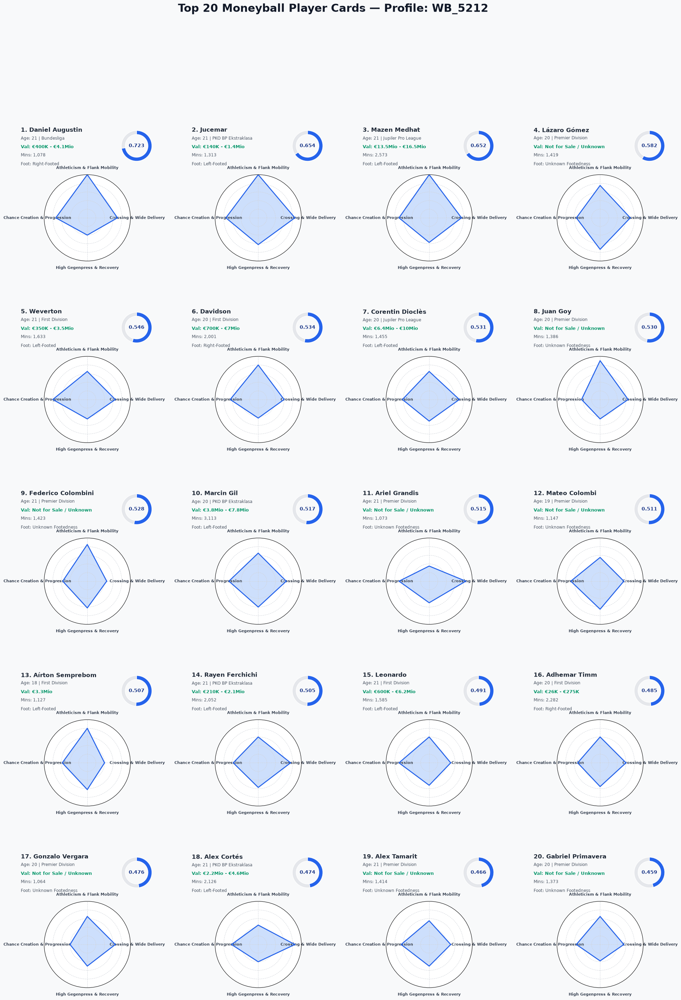

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


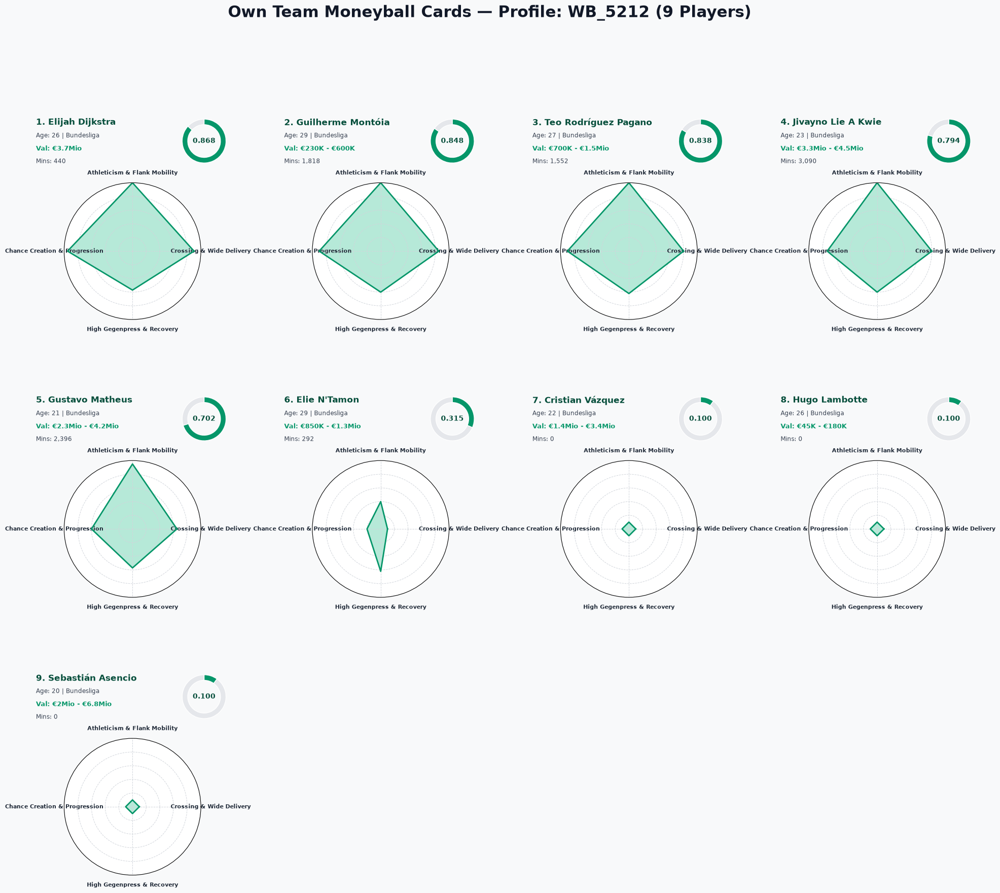

Cards successfully generated and saved to 'own_team_wb_5212_scouting_cards.png'
 Finished generating charts for profile: WB_5212

 Processing Profile: DM_Safety
 Target Positions: ['DM'] | Target Sides: ['C']


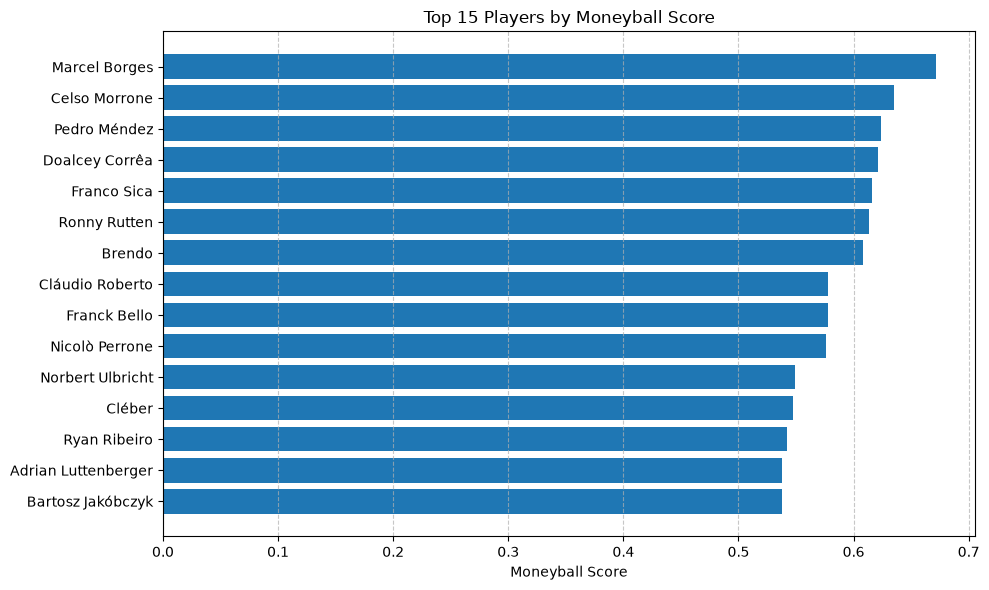

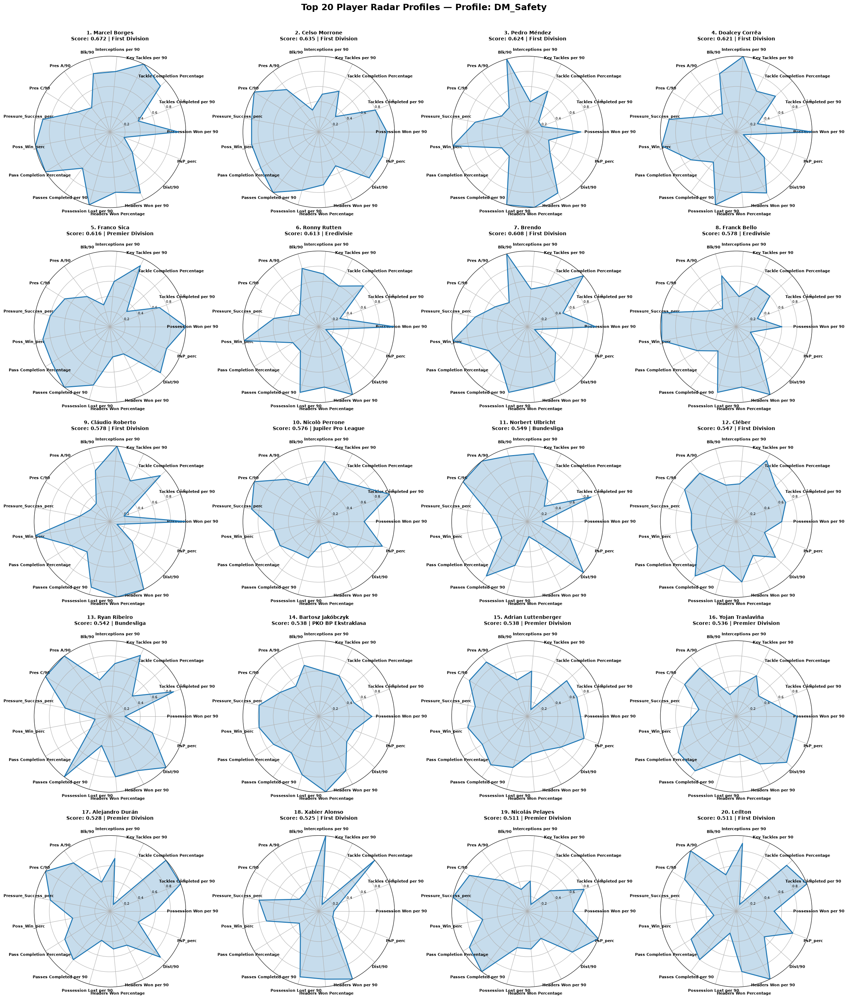

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


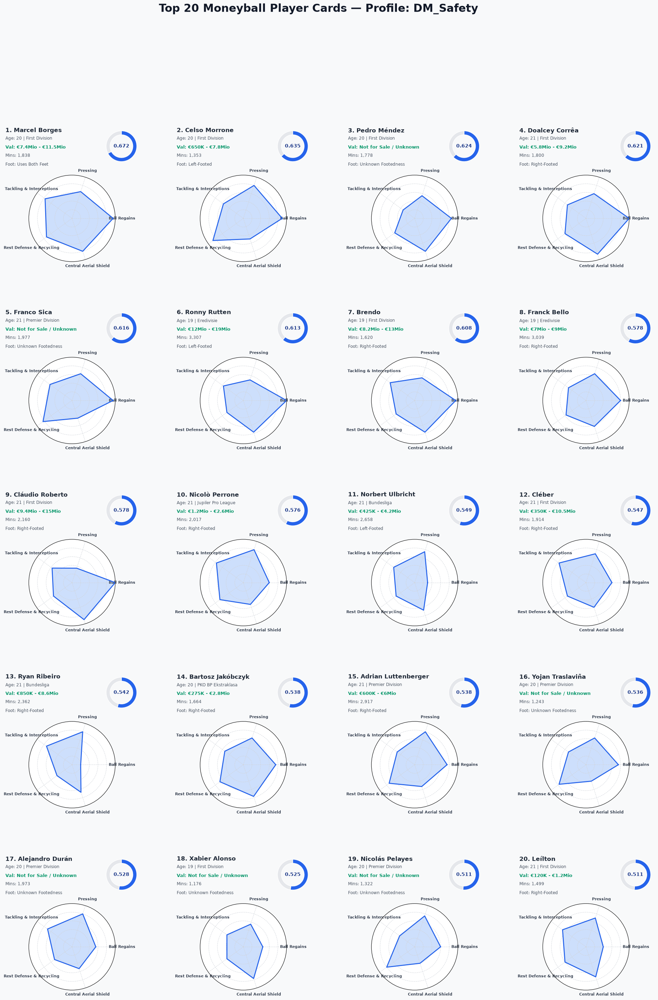

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


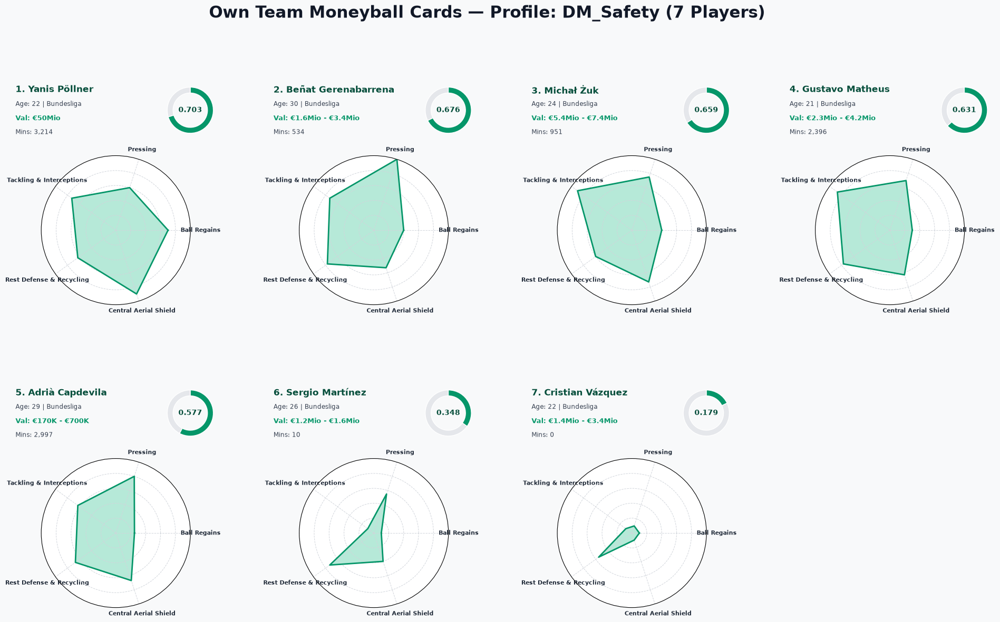

Cards successfully generated and saved to 'own_team_dm_safety_scouting_cards.png'
 Finished generating charts for profile: DM_Safety

 Processing Profile: DLP_Pressing
 Target Positions: ['DM'] | Target Sides: ['C']


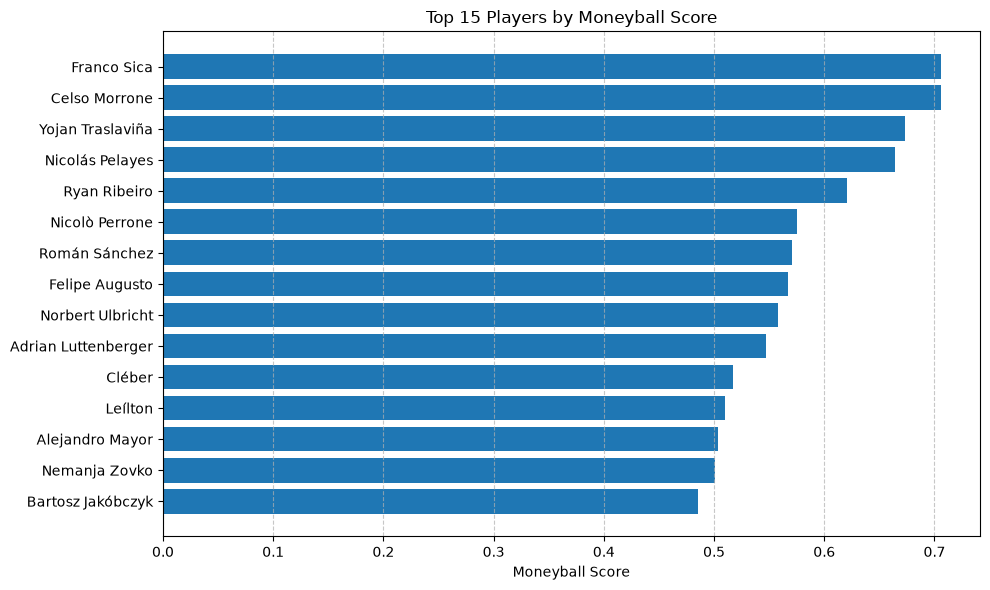

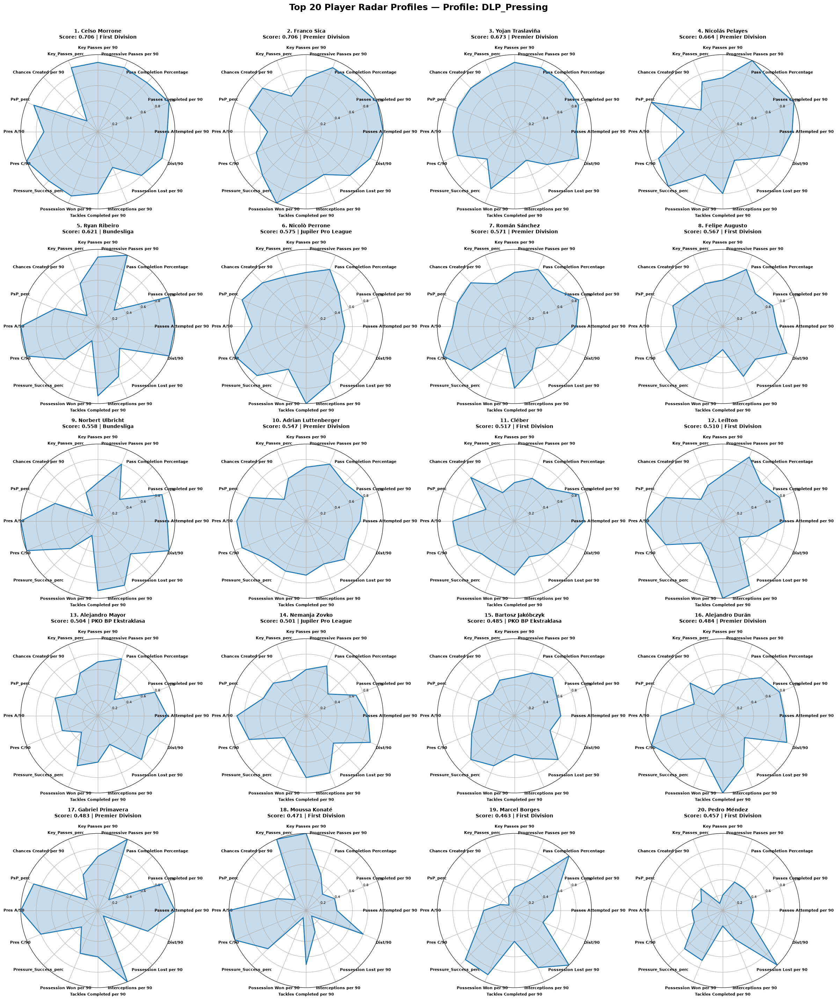

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


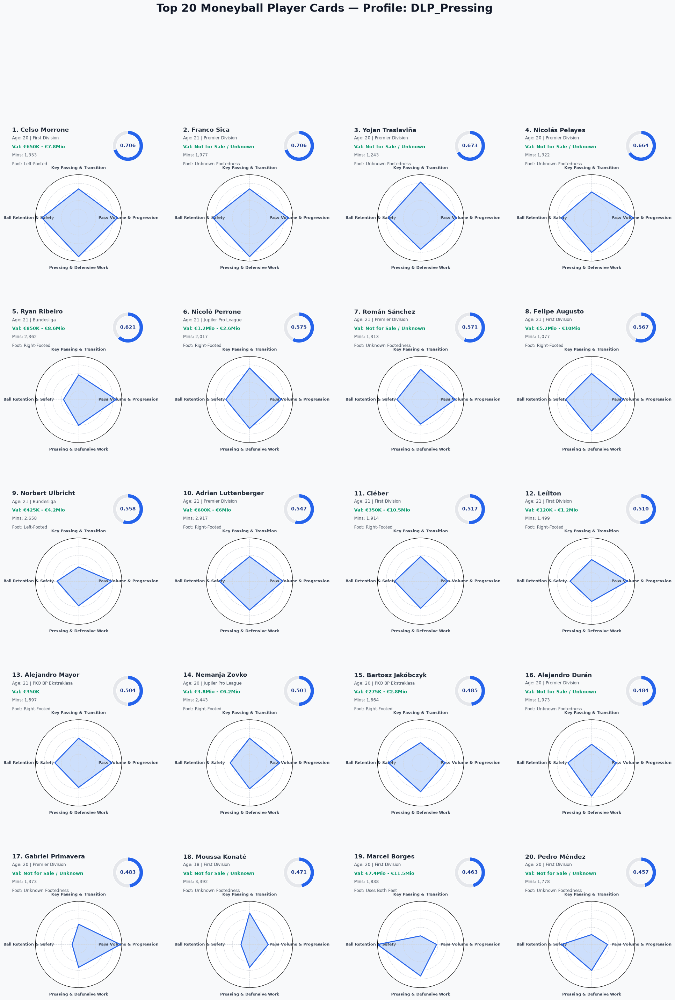

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


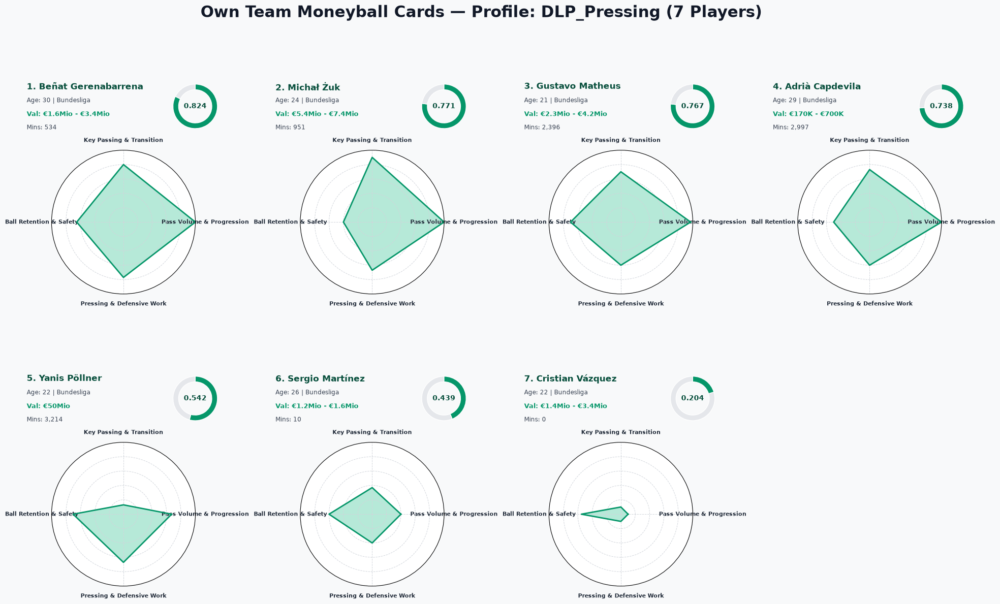

Cards successfully generated and saved to 'own_team_dlp_pressing_scouting_cards.png'
 Finished generating charts for profile: DLP_Pressing

 Processing Profile: AM_Playmaker
 Target Positions: ['AM'] | Target Sides: ['C']


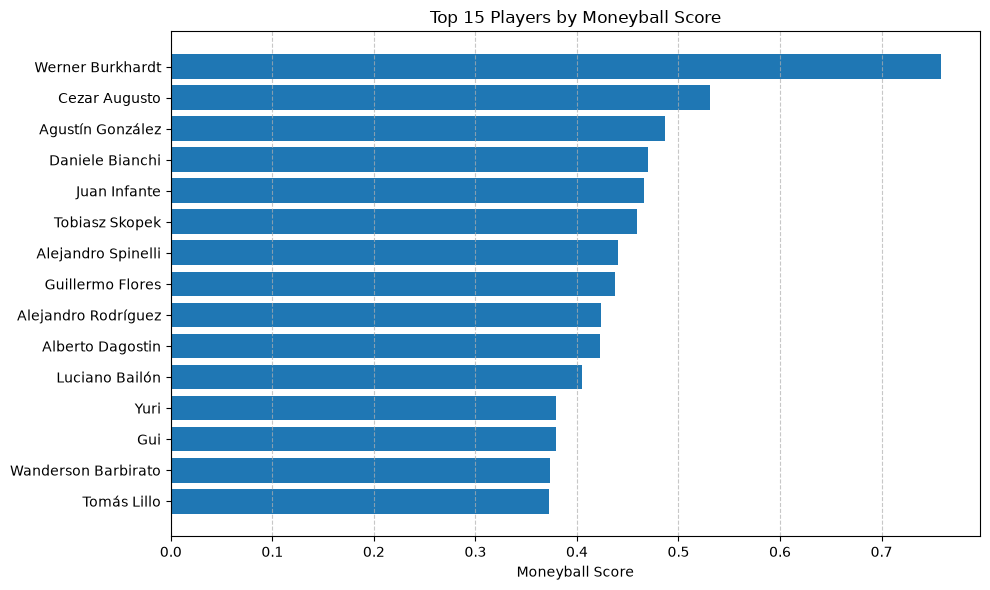

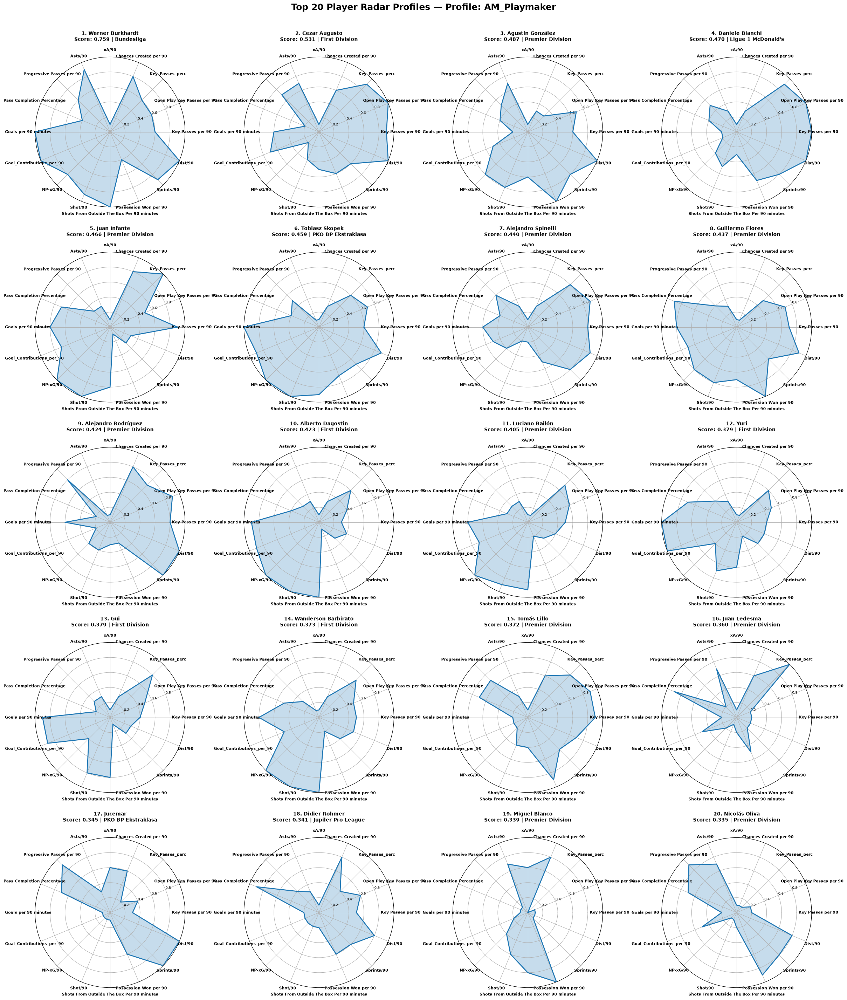

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


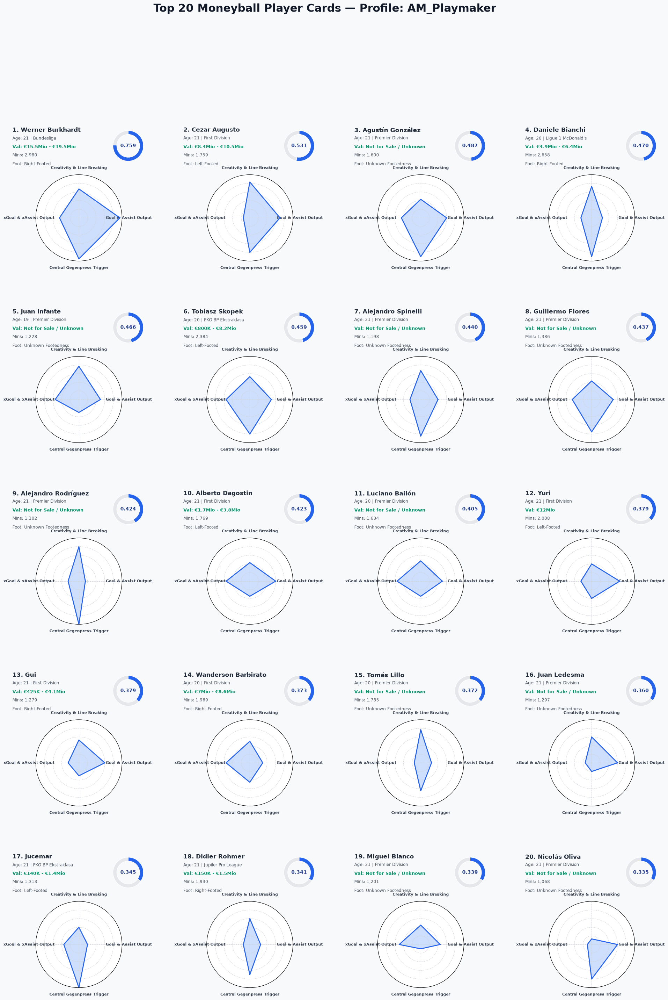

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


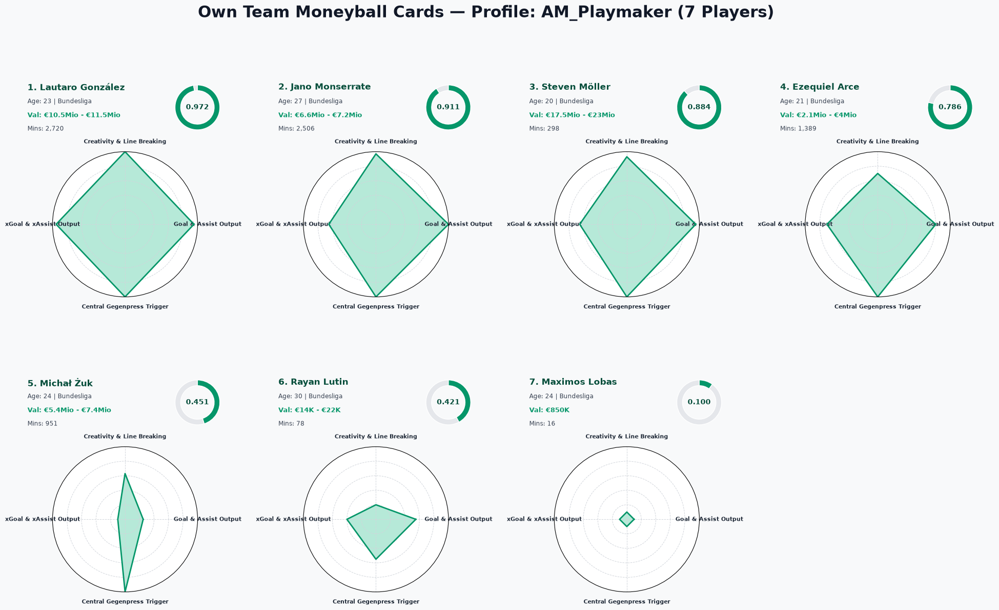

Cards successfully generated and saved to 'own_team_am_playmaker_scouting_cards.png'
 Finished generating charts for profile: AM_Playmaker

 Processing Profile: Target_FW
 Target Positions: ['ST'] | Target Sides: ['C']


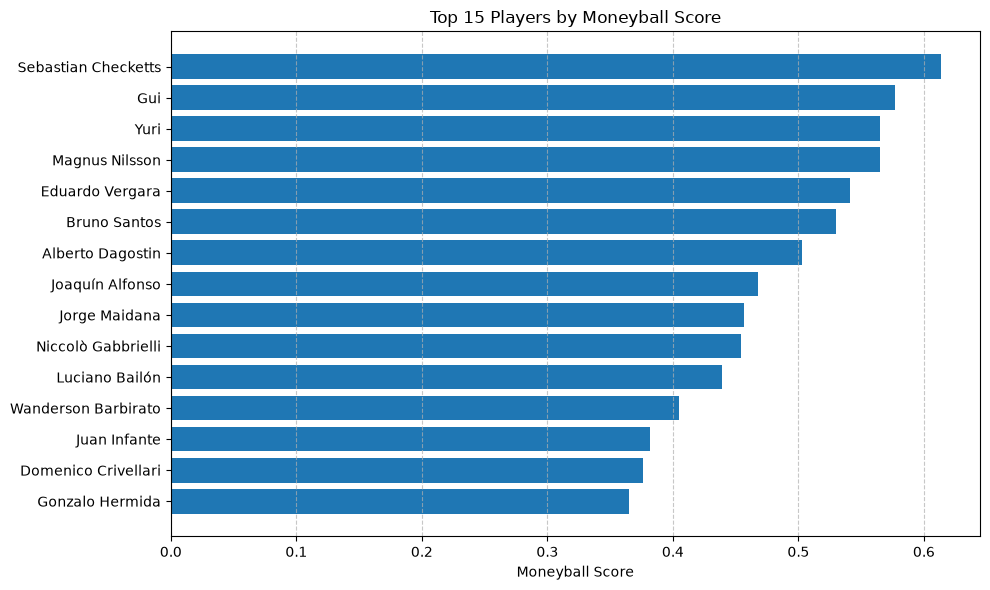

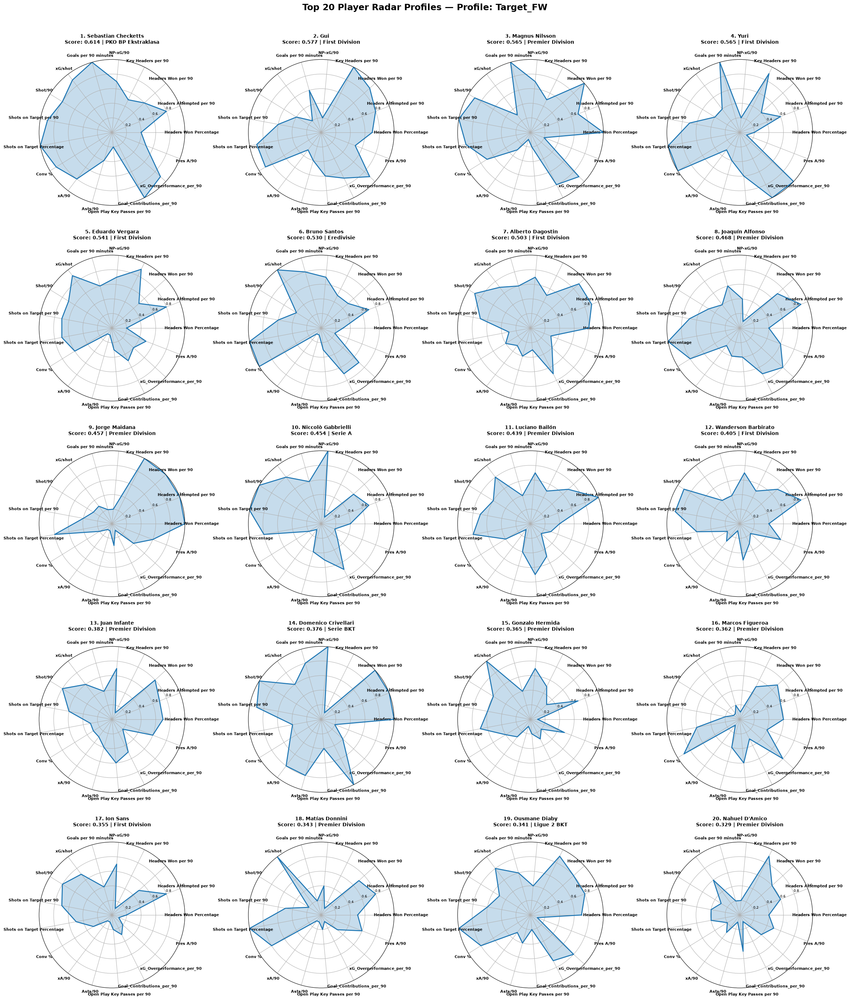

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


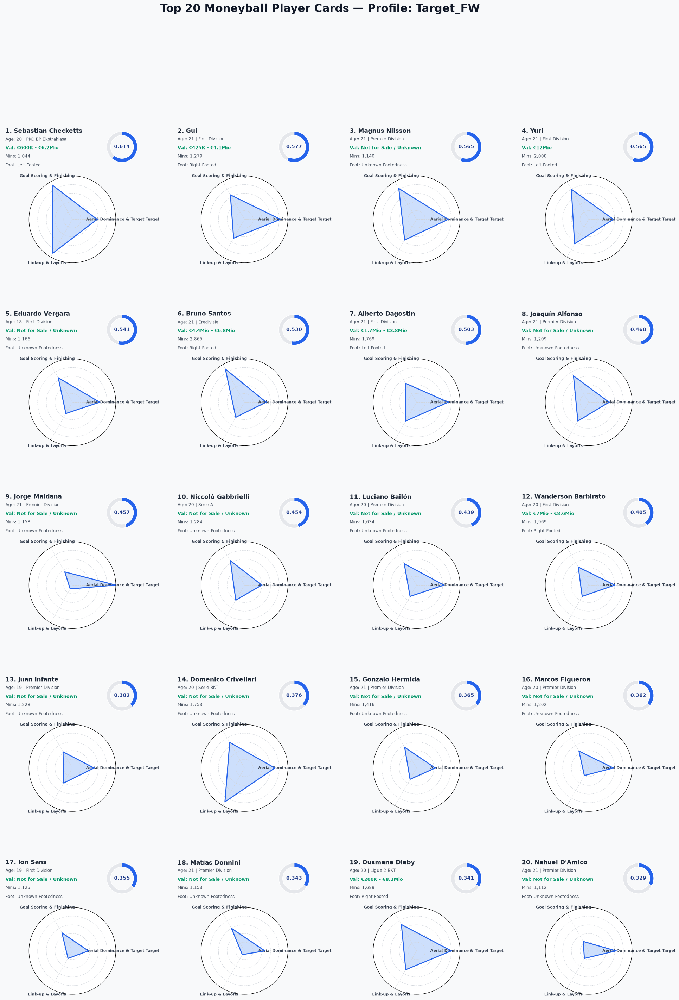

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


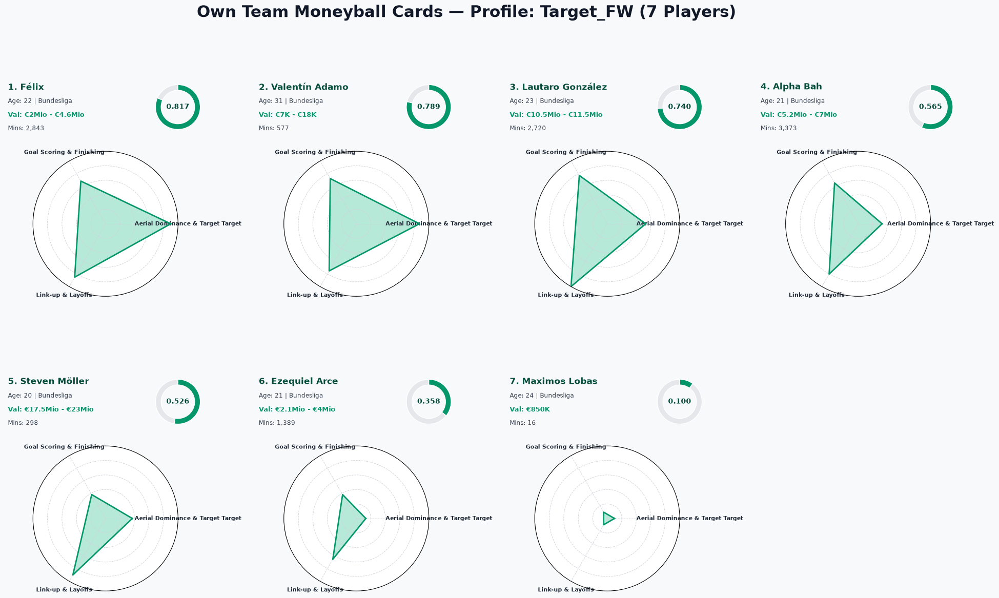

Cards successfully generated and saved to 'own_team_target_fw_scouting_cards.png'
 Finished generating charts for profile: Target_FW

 Processing Profile: ST_Classic
 Target Positions: ['ST'] | Target Sides: ['C']


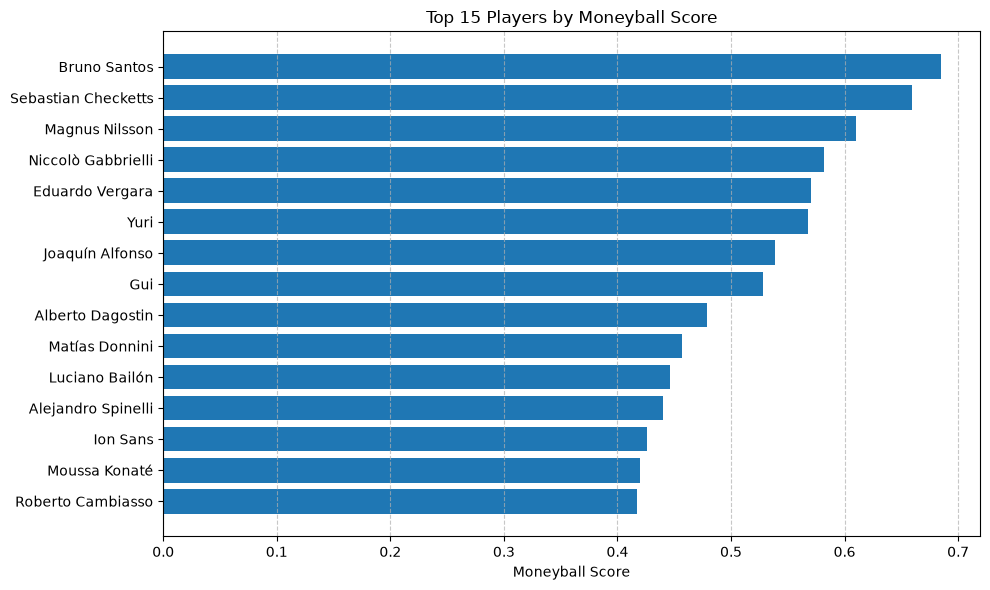

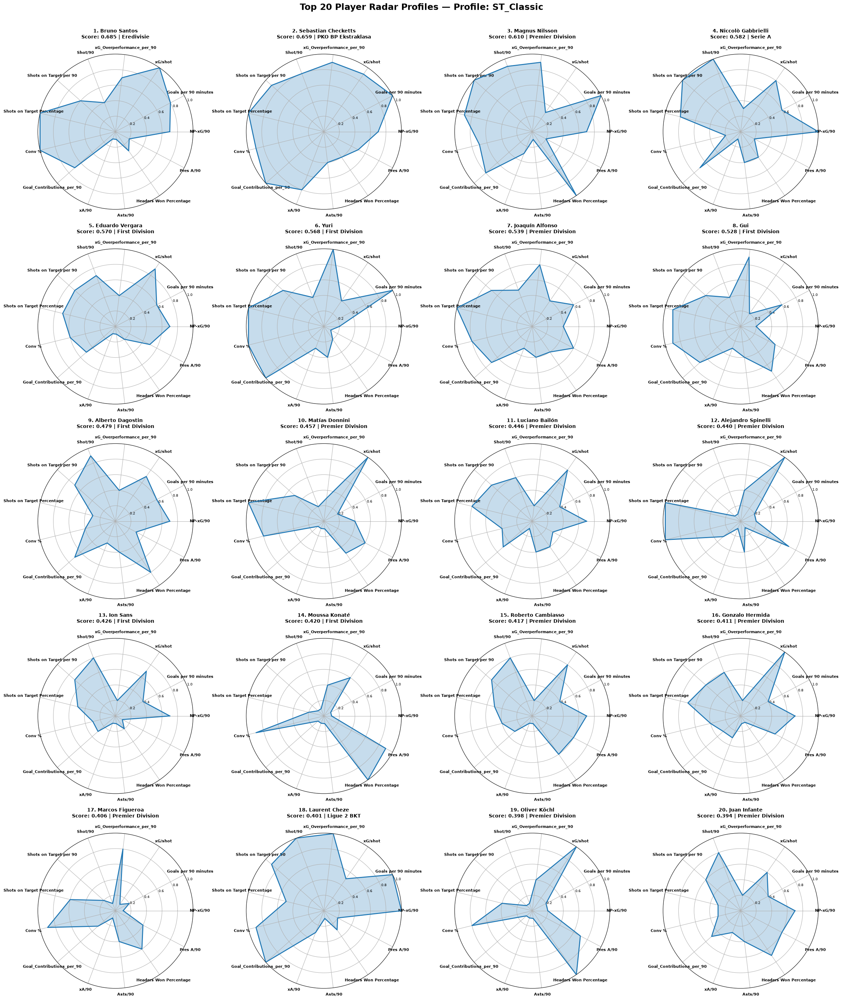

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:401: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


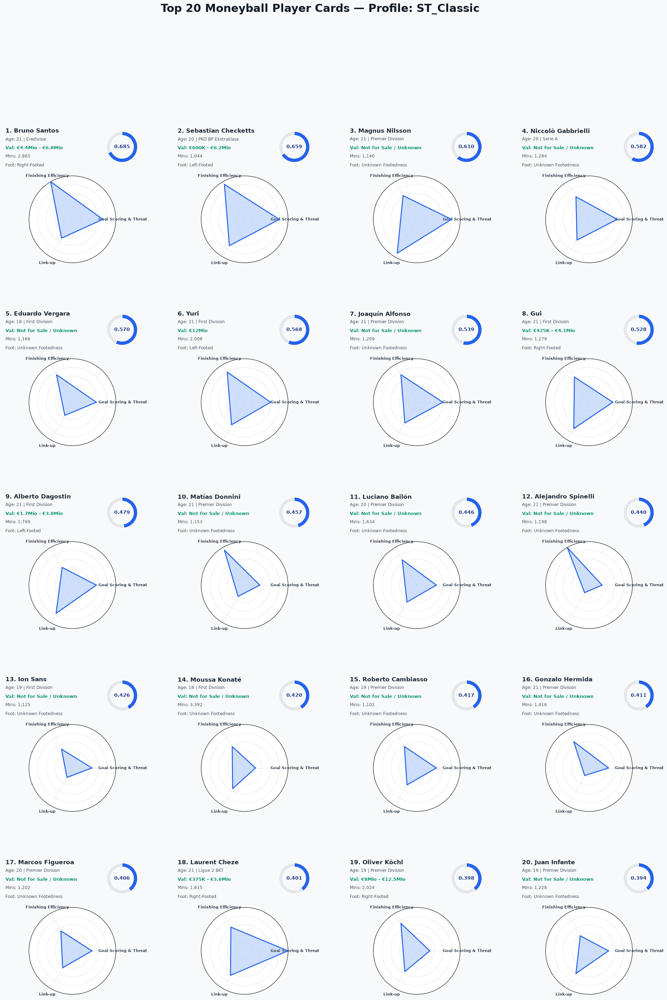

c:\Users\lasse\VSCode\moneyball\moneyball_logic\graphics.py:576: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


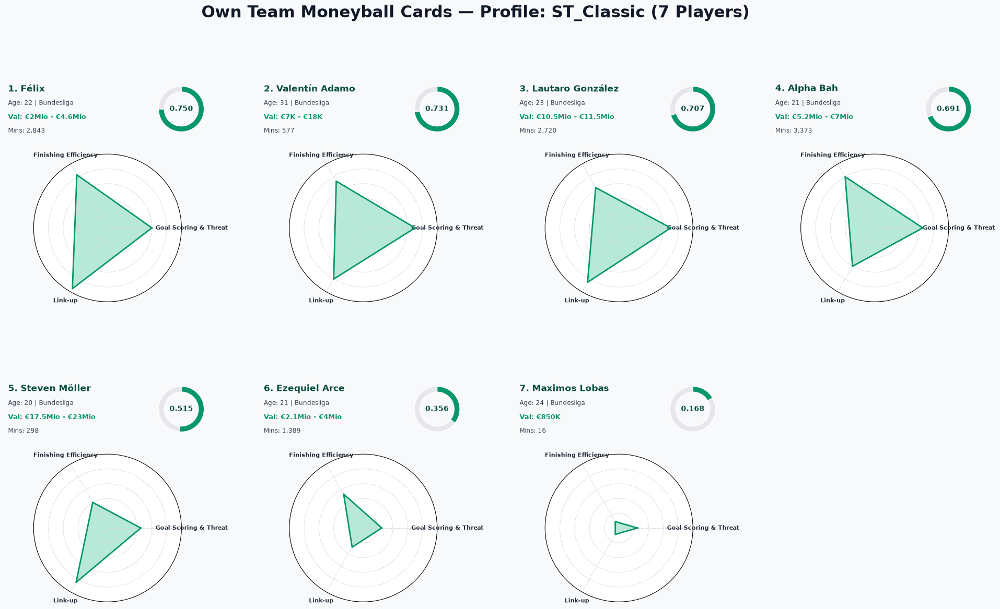

Cards successfully generated and saved to 'own_team_st_classic_scouting_cards.png'
 Finished generating charts for profile: ST_Classic


In [ ]:
import os
import yaml
from moneyball_logic import (
    apply_post_scoring_filters,
    calculate_moneyball_scores,
    filter_players_by_position,
    load_data,
    plot_own_team_scouting_cards,
    plot_scouting_cards,
    plot_top_20_spider_grid,
    plot_top_players,
    prepare_dataframe,
)

# ==============================================================================
# 1. FILE PATHS & SETUP
# ==============================================================================
file_path = "data/2026_bos_2BL.csv"
file_path_own_team = "data_own_team/2026_bos.csv"

output_dir = "output_charts"
os.makedirs(output_dir, exist_ok=True)

# ==============================================================================
# 2. READ CONFIG.YAML
# ==============================================================================
config_path = "config.yaml"

with open(config_path, "r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

general_cfg = config.get("general", {})

id_columns = general_cfg.get("id_columns", [])
positions_config = config.get("positions", {})


# Global Post-Scoring Filters
INVERSE_METRICS = ["Possession Lost per 90"]
MAX_TRANSFER_VALUE = 100_000_000
MIN_AGE = 15
MAX_AGE = 21


# ==============================================================================
# 3. LOAD DATA ONCE
# ==============================================================================
df_raw = load_data(file_path)
df_own_raw = load_data(file_path_own_team)

df_base = prepare_dataframe(df_raw, id_columns=id_columns)
df_own_base = prepare_dataframe(df_own_raw, id_columns=id_columns)

# ==============================================================================
# 4. AUTOMATED EXECUTION LOOP FOR ALL PROFILES
# ==============================================================================
for profile_name, profile_cfg in positions_config.items():
    print(f"\n==================================================")
    print(f" Processing Profile: {profile_name}")
    print(f"==================================================")

    # Extract target positions and sides directly from YAML
    selected_positions = profile_cfg.get("positions", [])
    selected_sides = profile_cfg.get("sides", [])

    print(f" Target Positions: {selected_positions} | Target Sides: {selected_sides}")

    # Positional & Side Filtering
    filtered_df = filter_players_by_position(
        df_base,
        selected_positions=selected_positions,
        selected_sides=selected_sides,
    )

    filtered_df_own_team = filter_players_by_position(
        df_own_base,
        selected_positions=selected_positions,
        selected_sides=selected_sides,
    )

    if filtered_df.empty:
        print(f" [Warning] No players found for profile '{profile_name}'. Skipping...")
        continue


    # Calculate Scores & Benchmark Own Team
    scored_df, scored_df_own_team = calculate_moneyball_scores(
        filtered_df=filtered_df,
        filtered_df_own_team=filtered_df_own_team,
        profile_cfg=profile_cfg,
        inverse_metrics=INVERSE_METRICS,
        config = general_cfg
    )

    # Post-Scoring Filters
    final_market_df = apply_post_scoring_filters(
        scored_df,
        min_age=MIN_AGE,
        max_age=MAX_AGE,
        max_transfer_val=MAX_TRANSFER_VALUE,
    )

    if final_market_df.empty:
        print(f" [Warning] No market players met filter criteria for '{profile_name}'. Skipping charts...")
        continue

    # --------------------------------------------------------------------------
    # GENERATE & SAVE CHARTS DYNAMICALLY
    # --------------------------------------------------------------------------
    clean_profile_filename = profile_name.lower()

    # 1. Bar Chart Overview
    plot_top_players(final_market_df, top_n=15)

    # 2. Individual Metrics Spider Grid (Top 20 Market Players)
    spider_path = os.path.join(output_dir, f"{clean_profile_filename}_top_20_spider_grid.png")
    plot_top_20_spider_grid(
        scored_df=final_market_df,
        profile_name=profile_name,
        save_filename=spider_path,
    )

    # 3. Market Scouting Cards (Top 20 Market Players)
    scouting_path = os.path.join(output_dir, f"{clean_profile_filename}_top_20_scouting_cards.png")
    plot_scouting_cards(
        scored_df=final_market_df,
        profile_name=profile_name,
        save_filename=scouting_path,
    )

    # 4. Own Team Scouting Cards
    if not scored_df_own_team.empty:
        own_scouting_path = os.path.join(output_dir, f"{clean_profile_filename}_own_team_scouting_cards.png")
        plot_own_team_scouting_cards(
            own_team_df=scored_df_own_team,
            profile_name=profile_name,
            # Pass save_filename if your plot_own_team_scouting_cards supports it:
            # save_filename=own_scouting_path,
        )

    print(f" Finished generating charts for profile: {profile_name}")